In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv('/content/train.csv', parse_dates=['Date'], low_memory=False)
store = pd.read_csv('/content/store.csv')

print(train.shape)
print(store.shape)
train.head()

(1017209, 9)
(1115, 10)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [9]:
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [2]:
train.shape

(1017209, 9)

In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[ns]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  object        
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[ns](1), int64(7), object(1)
memory usage: 69.8+ MB


In [4]:
train['Store'].nunique()

1115

In [6]:
print(store.shape)

(1115, 10)


In [7]:
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assortment                 1115 non-null   object 
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    object 
dtypes: float64(5), int64(2), object(3)
memory usage: 87.2+ KB


In [8]:
store.isnull().sum()

,0
Store,0
StoreType,0
Assortment,0
CompetitionDistance,3
CompetitionOpenSinceMonth,354
CompetitionOpenSinceYear,354
Promo2,0
Promo2SinceWeek,544
Promo2SinceYear,544
PromoInterval,544


In [10]:
print(train['Date'].min(), train['Date'].max())
print(train['Open'].value_counts())
print((train['Sales'] == 0).sum())

2013-01-01 00:00:00 2015-07-31 00:00:00
Open
1    844392
0    172817
Name: count, dtype: int64
172871


In [11]:
df = train.merge(store, on='Store', how='left')
print(df.shape)
df.isnull().sum()

(1017209, 18)


,0
Store,0
DayOfWeek,0
Date,0
Sales,0
Customers,0
Open,0
Promo,0
StateHoliday,0
SchoolHoliday,0
StoreType,0


In [19]:
df['CompetitionDistance'] = df['CompetitionDistance'].fillna(df['CompetitionDistance'].median())

In [20]:
df['CompetitionOpenSinceMonth'] = df['CompetitionOpenSinceMonth'].fillna(df['Date'].dt.month)

In [21]:
df['CompetitionOpenSinceYear'] = df['CompetitionOpenSinceYear'].fillna(df['Date'].dt.year)

In [22]:
df['Promo2SinceWeek'] = df['Promo2SinceWeek'].fillna(0)

In [23]:
df['Promo2SinceYear'] = df['Promo2SinceYear'].fillna(0)

In [24]:
df['PromoInterval'] = df['PromoInterval'].fillna('None')

In [25]:
print(df.isnull().sum())
print(df.shape)

Store                        0
DayOfWeek                    0
Date                         0
Sales                        0
Customers                    0
Open                         0
Promo                        0
StateHoliday                 0
SchoolHoliday                0
StoreType                    0
Assortment                   0
CompetitionDistance          0
CompetitionOpenSinceMonth    0
CompetitionOpenSinceYear     0
Promo2                       0
Promo2SinceWeek              0
Promo2SinceYear              0
PromoInterval                0
dtype: int64
(1017209, 18)


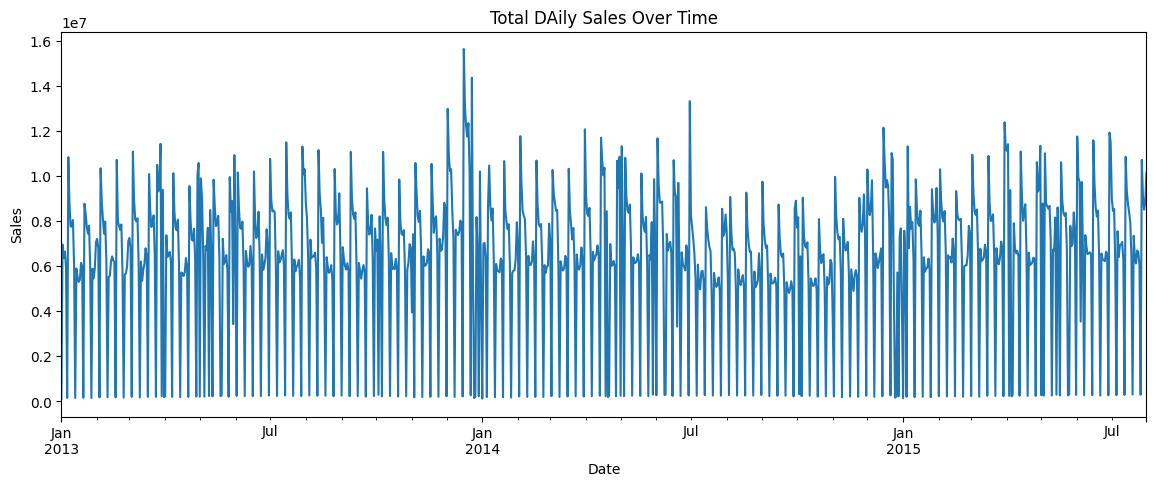

In [26]:
daily_sales = df.groupby('Date')['Sales'].sum()
plt.figure(figsize=(14,5))
daily_sales.plot()
plt.title('Total DAily Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.show()

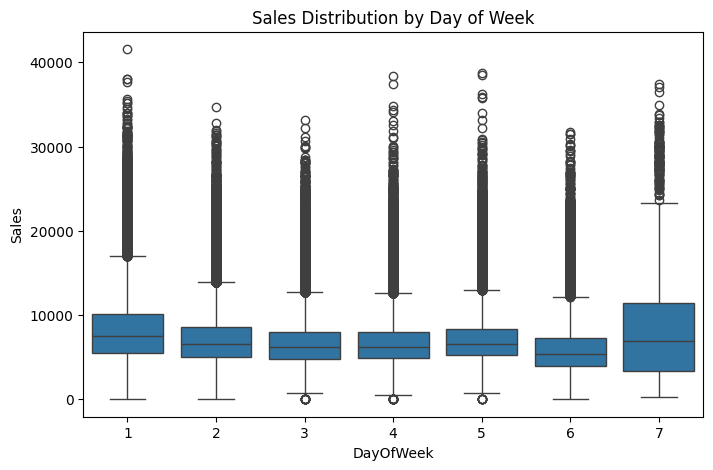

In [27]:
plt.figure(figsize=(8,5))
sns.boxplot(x='DayOfWeek', y='Sales', data=df[df['Open']==1])
plt.title('Sales Distribution by Day of Week')
plt.show()

In [28]:
print(df.groupby('Promo')['Sales'].mean())

Promo
0    4406.050805
1    7991.152046
Name: Sales, dtype: float64


In [29]:
print(df.groupby('StoreType')['Sales'].mean())

StoreType
a     5738.179710
b    10058.837334
c     5723.629246
d     5641.819243
Name: Sales, dtype: float64


In [30]:
df = df[df['Open'] == 1].copy()
print(df.shape)

(844392, 18)


In [31]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)

df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,Day,WeekOfYear
0,1,5,2015-07-31,5263,555,1,1,0,1,c,...,9.0,2008.0,0,0.0,0.0,None,2015,7,31,31
1,2,5,2015-07-31,6064,625,1,1,0,1,a,...,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",2015,7,31,31
2,3,5,2015-07-31,8314,821,1,1,0,1,a,...,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",2015,7,31,31
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,...,9.0,2009.0,0,0.0,0.0,None,2015,7,31,31
4,5,5,2015-07-31,4822,559,1,1,0,1,a,...,4.0,2015.0,0,0.0,0.0,None,2015,7,31,31


In [32]:
df['CompetitionOpen'] = 12 * (df['Year'] - df['CompetitionOpenSinceYear']) + \
                             (df['Month'] - df['CompetitionOpenSinceMonth'])
df['CompetitionOpen'] = df['CompetitionOpen'].apply(lambda x: x if x > 0 else 0)


In [33]:
month_map = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',
             7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}
df['MonthStr'] = df['Month'].map(month_map)


In [34]:
df['IsPromo2Active'] = df.apply(
    lambda row: 1 if (row['Promo2'] == 1 and row['PromoInterval'] != 'None'
                       and row['MonthStr'] in row['PromoInterval'].split(',')) else 0, axis=1)

In [35]:
df.drop('MonthStr', axis=1, inplace=True)
print(df[['CompetitionOpen', 'IsPromo2Active']].describe())
print(df['IsPromo2Active'].value_counts())

       CompetitionOpen  IsPromo2Active
count    844392.000000   844392.000000
mean         41.953548        0.165988
std          65.189741        0.372070
min           0.000000        0.000000
25%           0.000000        0.000000
50%          16.000000        0.000000
75%          73.000000        0.000000
max        1386.000000        1.000000
IsPromo2Active
0    704233
1    140159
Name: count, dtype: int64


In [36]:
df = df.sort_values(['Store', 'Date']).reset_index(drop=True)

In [38]:
df[['Store', 'Date']].head(10)

,Store,Date
0,1,2013-01-02
1,1,2013-01-03
2,1,2013-01-04
3,1,2013-01-05
4,1,2013-01-07
5,1,2013-01-08
6,1,2013-01-09
7,1,2013-01-10
8,1,2013-01-11
9,1,2013-01-12


In [39]:
df['Sales_Lag_1'] = df.groupby('Store')['Sales'].shift(1)
df['Sales_Lag_7'] = df.groupby('Store')['Sales'].shift(7)
df['Sales_Lag_14'] = df.groupby('Store')['Sales'].shift(14)

df['Sales_RollingMean_7'] = df.groupby('Store')['Sales'].transform(
    lambda x: x.shift(1).rolling(window=7).mean()
)
df['Sales_RollingMean_30'] = df.groupby('Store')['Sales'].transform(
    lambda x: x.shift(1).rolling(window=30).mean()
)

print(df[['Store','Date','Sales','Sales_Lag_1','Sales_Lag_7','Sales_RollingMean_7']].head(15))
print(df.isnull().sum().sum())

    Store       Date  Sales  Sales_Lag_1  Sales_Lag_7  Sales_RollingMean_7
0       1 2013-01-02   5530          NaN          NaN                  NaN
1       1 2013-01-03   4327       5530.0          NaN                  NaN
2       1 2013-01-04   4486       4327.0          NaN                  NaN
3       1 2013-01-05   4997       4486.0          NaN                  NaN
4       1 2013-01-07   7176       4997.0          NaN                  NaN
5       1 2013-01-08   5580       7176.0          NaN                  NaN
6       1 2013-01-09   5471       5580.0          NaN                  NaN
7       1 2013-01-10   4892       5471.0       5530.0          5366.714286
8       1 2013-01-11   4881       4892.0       4327.0          5275.571429
9       1 2013-01-12   4952       4881.0       4486.0          5354.714286
10      1 2013-01-14   4717       4952.0       4997.0          5421.285714
11      1 2013-01-15   3900       4717.0       7176.0          5381.285714
12      1 2013-01-16   40

In [40]:
before = df.shape[0]
df = df.dropna(subset=['Sales_Lag_1','Sales_Lag_7','Sales_Lag_14',
                        'Sales_RollingMean_7','Sales_RollingMean_30']).reset_index(drop=True)
after = df.shape[0]
print(f"Dropped {before - after} rows, {after} rows remain")
print(df.isnull().sum().sum())

Dropped 33450 rows, 810942 rows remain
0


In [41]:
print(df['StoreType'].unique())
print(df['Assortment'].unique())
print(df['StateHoliday'].unique())

['c' 'a' 'd' 'b']
['a' 'c' 'b']
['0' 'a' 'b' 'c']


In [42]:
cat_cols = ['StoreType', 'Assortment', 'StateHoliday']
for col in cat_cols:
    df[col] = df[col].astype('category')

print(df.dtypes[cat_cols])

StoreType       category
Assortment      category
StateHoliday    category
dtype: object


In [43]:
feature_cols = [
    'Store', 'DayOfWeek', 'Promo', 'StateHoliday', 'SchoolHoliday',
    'StoreType', 'Assortment', 'CompetitionDistance', 'Promo2',
    'Year', 'Month', 'Day', 'WeekOfYear',
    'CompetitionOpen', 'IsPromo2Active',
    'Sales_Lag_1', 'Sales_Lag_7', 'Sales_Lag_14',
    'Sales_RollingMean_7', 'Sales_RollingMean_30'
]
target_col = 'Sales'

print(len(feature_cols))
print(df[feature_cols].dtypes)

20
Store                      int64
DayOfWeek                  int64
Promo                      int64
StateHoliday            category
SchoolHoliday              int64
StoreType               category
Assortment              category
CompetitionDistance      float64
Promo2                     int64
Year                       int32
Month                      int32
Day                        int32
WeekOfYear                 int64
CompetitionOpen          float64
IsPromo2Active             int64
Sales_Lag_1              float64
Sales_Lag_7              float64
Sales_Lag_14             float64
Sales_RollingMean_7      float64
Sales_RollingMean_30     float64
dtype: object


In [44]:
split_date = df['Date'].max() - pd.Timedelta(weeks=6)
print(f"Split date: {split_date}")

train_df = df[df['Date'] <= split_date]
test_df = df[df['Date'] > split_date]

print(f"Train: {train_df.shape}, Test: {test_df.shape}")
print(f"Train dates: {train_df['Date'].min()} to {train_df['Date'].max()}")
print(f"Test dates: {test_df['Date'].min()} to {test_df['Date'].max()}")

Split date: 2015-06-19 00:00:00
Train: (770660, 29), Test: (40282, 29)
Train dates: 2013-01-31 00:00:00 to 2015-06-19 00:00:00
Test dates: 2015-06-20 00:00:00 to 2015-07-31 00:00:00


In [45]:
!pip install lightgbm -q

import lightgbm as lgb
from sklearn.metrics import mean_squared_error, mean_absolute_error

X_train = train_df[feature_cols]
y_train = train_df[target_col]
X_test = test_df[feature_cols]
y_test = test_df[target_col]

cat_features = ['StoreType', 'Assortment', 'StateHoliday']

train_data = lgb.Dataset(X_train, label=y_train, categorical_feature=cat_features)
test_data = lgb.Dataset(X_test, label=y_test, categorical_feature=cat_features, reference=train_data)

params = {
    'objective': 'regression',
    'metric': 'rmse',
    'learning_rate': 0.05,
    'num_leaves': 64,
    'verbose': -1
}

model = lgb.train(
    params,
    train_data,
    num_boost_round=1000,
    valid_sets=[train_data, test_data],
    valid_names=['train', 'test'],
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)]
)

preds = model.predict(X_test, num_iteration=model.best_iteration)

rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)
mape = np.mean(np.abs((y_test - preds) / y_test)) * 100

print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"MAPE: {mape:.2f}%")

Training until validation scores don't improve for 50 rounds
[100]	train's rmse: 976.826	test's rmse: 970.157
[200]	train's rmse: 878.802	test's rmse: 908.939
[300]	train's rmse: 838.013	test's rmse: 880.222
[400]	train's rmse: 809.971	test's rmse: 865.123
[500]	train's rmse: 789.526	test's rmse: 853.458
[600]	train's rmse: 773.823	test's rmse: 848.926
[700]	train's rmse: 757.392	test's rmse: 840.322
[800]	train's rmse: 744.027	test's rmse: 834.089
[900]	train's rmse: 734.391	test's rmse: 831.125
[1000]	train's rmse: 724.286	test's rmse: 828.013
Did not meet early stopping. Best iteration is:
[996]	train's rmse: 724.7	test's rmse: 827.58
RMSE: 827.58
MAE: 581.49
MAPE: 8.86%


In [46]:
model = lgb.train(
    params,
    train_data,
    num_boost_round=3000,
    valid_sets=[train_data, test_data],
    valid_names=['train', 'test'],
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)]
)

preds = model.predict(X_test, num_iteration=model.best_iteration)

rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)
mape = np.mean(np.abs((y_test - preds) / y_test)) * 100

print(f"Best iteration: {model.best_iteration}")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"MAPE: {mape:.2f}%")

Training until validation scores don't improve for 100 rounds
[200]	train's rmse: 878.802	test's rmse: 908.939
[400]	train's rmse: 809.971	test's rmse: 865.123
[600]	train's rmse: 773.823	test's rmse: 848.926
[800]	train's rmse: 744.027	test's rmse: 834.089
[1000]	train's rmse: 724.286	test's rmse: 828.013
[1200]	train's rmse: 708.496	test's rmse: 823.339
[1400]	train's rmse: 692.806	test's rmse: 815.271
[1600]	train's rmse: 679.27	test's rmse: 809.927
[1800]	train's rmse: 666.732	test's rmse: 804.034
[2000]	train's rmse: 654.095	test's rmse: 799.501
[2200]	train's rmse: 643.718	test's rmse: 795.369
[2400]	train's rmse: 633.893	test's rmse: 791.783
[2600]	train's rmse: 625.797	test's rmse: 789.563
[2800]	train's rmse: 618.452	test's rmse: 786.738
[3000]	train's rmse: 611.191	test's rmse: 784.733
Did not meet early stopping. Best iteration is:
[2990]	train's rmse: 611.515	test's rmse: 784.629
Best iteration: 2990
RMSE: 784.63
MAE: 550.84
MAPE: 8.32%


                 feature    importance
15           Sales_Lag_1  2.669760e+13
19  Sales_RollingMean_30  2.499035e+13
2                  Promo  7.857281e+12
1              DayOfWeek  5.487586e+12
11                   Day  1.928050e+12
12            WeekOfYear  1.351355e+12
7    CompetitionDistance  1.012417e+12
10                 Month  9.087466e+11
0                  Store  8.277565e+11
5              StoreType  5.965813e+11
18   Sales_RollingMean_7  5.450065e+11
13       CompetitionOpen  2.673140e+11
16           Sales_Lag_7  2.594444e+11
9                   Year  1.962051e+11
17          Sales_Lag_14  1.960520e+11
6             Assortment  1.415825e+11
4          SchoolHoliday  1.392200e+11
8                 Promo2  1.047027e+11
3           StateHoliday  8.378283e+10
14        IsPromo2Active  3.648182e+10


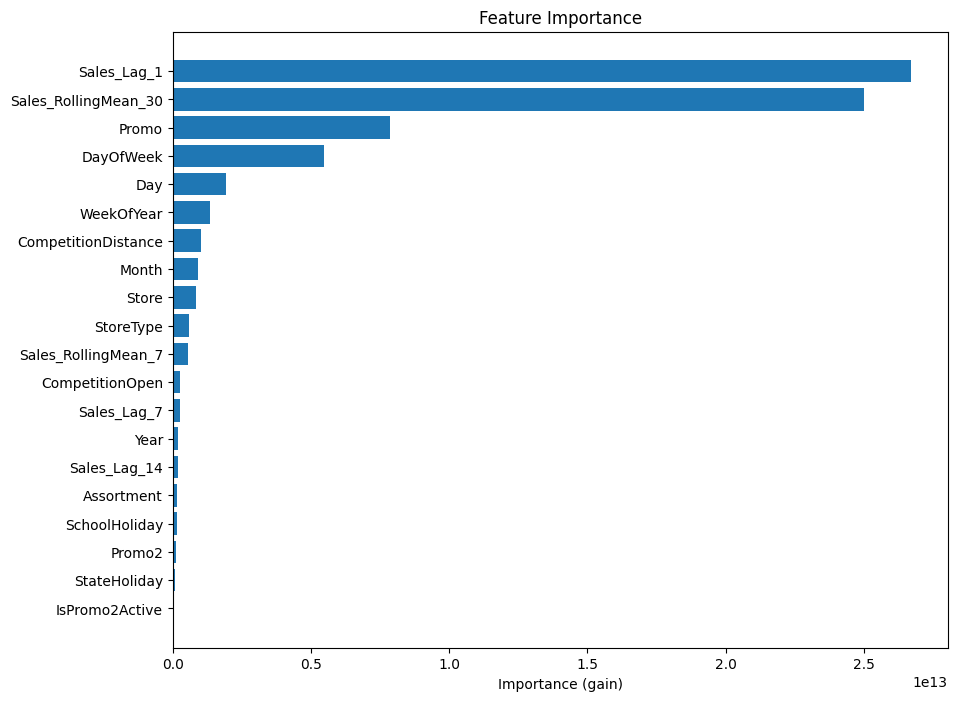

In [47]:
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': model.feature_importance(importance_type='gain')
}).sort_values('importance', ascending=False)

print(importance)

plt.figure(figsize=(10,8))
plt.barh(importance['feature'], importance['importance'])
plt.xlabel('Importance (gain)')
plt.title('Feature Importance')
plt.gca().invert_yaxis()
plt.show()

In [48]:
import joblib

joblib.dump(model, 'demand_forecast_model.pkl')
joblib.dump(feature_cols, 'feature_cols.pkl')
joblib.dump(cat_features, 'cat_features.pkl')

store_latest = df.sort_values('Date').groupby('Store').tail(1)[
    ['Store','StoreType','Assortment','CompetitionDistance','Promo2',
     'Sales_Lag_1','Sales_Lag_7','Sales_Lag_14',
     'Sales_RollingMean_7','Sales_RollingMean_30']
]
store_latest.to_csv('store_latest_info.csv', index=False)

from google.colab import files
files.download('demand_forecast_model.pkl')
files.download('feature_cols.pkl')
files.download('cat_features.pkl')
files.download('store_latest_info.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>